# 03 · Stationarity and SARIMA deep dive (TOTAL series)

**Notation.** SARIMA(p,d,q)(P,D,Q)[s]:
- **p** autoregressive terms: this week depends on the last p weeks;
- **d** ordinary differences: model week-to-week *changes* instead of levels (removes trend);
- **q** moving-average terms: this week depends on the last q *shocks* (forecast errors);
- **P, D, Q** the same three ideas at the **seasonal lag s** (here s = 52: same week last year).

**Protocol.** Orders are *identified* using only weeks 0-211 (the training data of CV fold 1). They are then *evaluated* on the 4 CV folds and the holdout, with parameters re-estimated at each origin. The order choice therefore never sees the data it is scored on.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
def show(fig): display(Image(filename=f"reports/figures/{fig}"))
def J(path): return json.load(open(path))

In [2]:
import contextlib, io
from src.analysis import sarima_deep_dive
with contextlib.redirect_stdout(io.StringIO()):
    sarima_deep_dive.main()
S = J("reports/sarima_deep_dive.json")
print("deep dive regenerated in this notebook")

deep dive regenerated in this notebook


## 1. Choosing d and D from tests, not by guessing
- **d:** repeated KPSS tests on the identification window (`ndiffs`), consistent with notebook 02, where all 21 aggregates became stationary after one difference.
- **D:** seasonal-strength test (`nsdiffs`, `seas`): D = 1 if F_S > 0.64.
- **Over-differencing risk:** each unnecessary difference adds a unit root to the MA side (residual lag-1 ACF near -0.5) and inflates forecast variance. We check this in the residual ACF below.

In [3]:
print("ndiffs (KPSS) =", S["ndiffs_kpss"], "| nsdiffs (seasonal strength) =", S["nsdiffs_seas"])
print("STL strengths on identification window:", {k: round(v, 3) for k, v in S["stl_strengths_ident"].items()})
print("=> d, D =", S["chosen_d_D"])

ndiffs (KPSS) = 1 | nsdiffs (seasonal strength) = 1
STL strengths on identification window: {'trend': 0.886, 'seasonal': 0.684}
=> d, D = [1, 1]


## 2. Order selection by AICc over a small, justified grid
**Space:** p ∈ {0..3}, q ∈ {0..2}, P ∈ {0,1}, Q ∈ {0,1} (48 models). Higher seasonal orders at s = 52 would need several more years of data to estimate.
**Why AICc:** it trades fit against complexity (with a small-sample correction), so we don't simply pick the most complex model.
**Its limit:** AICc measures *in-sample* fit under model assumptions. It does not guarantee out-of-sample accuracy, so the top candidates are re-checked on CV.

In [4]:
g = pd.read_csv("reports/tables/sarima_total_aicc_grid.csv")
print("grid of", S["grid_size"], "models fitted in", S["grid_seconds"], "s")
display(g.head(8).round(1))
tcv = pd.read_csv("reports/tables/sarima_total_top_aicc_vs_cv.csv")
display(tcv.round(4))

grid of 48 models fitted in 49.7 s


,p,q,P,Q,aicc,aic,bic,sigma2
0,3,2,0,1,3337.4,3336.7,3358.2,68371580.9
1,3,0,0,0,3340.1,3339.9,3352.1,75108923.8
2,3,0,0,1,3340.3,3339.9,3355.3,72897823.5
3,0,2,0,0,3340.5,3340.4,3349.6,75854288.4
4,0,2,0,1,3341.2,3340.9,3353.2,75062012.3
5,2,1,0,0,3341.2,3341.0,3353.2,75641508.9
6,3,0,1,0,3341.9,3341.5,3356.9,74780505.4
7,0,2,1,0,3341.9,3341.7,3353.9,75749620.0


,order,aicc,cv_mean_MASE,cv_mean_WAPE,holdout_WAPE,aicc_rank,cv_rank
0,"(3,1,2)(0,1,1)[52]",3337.4372,0.3092,0.0266,0.0212,1,3
1,"(3,1,0)(0,1,0)[52]",3340.1210,0.3130,0.0270,0.0211,2,4
2,"(3,1,0)(0,1,1)[52]",3340.3369,0.3005,0.0258,0.0231,3,1
3,"(0,1,2)(0,1,0)[52]",3340.5323,0.3193,0.0275,0.0243,4,5
4,"(0,1,2)(0,1,1)[52]",3341.1746,0.3010,0.0258,0.0255,5,2
5,"(2,1,1)(0,1,0)[52]",3341.2267,0.3222,0.0277,0.0246,6,6


**Observed:** the AICc winner is **SARIMA(3,1,2)(0,1,1)[52]**, but the top 6 models lie within about 4 AICc units of each other, and their out-of-sample ranks differ from the AICc ranks: the AICc #3, (3,1,0)(0,1,1), has the best CV MASE (0.301 vs 0.309). All six score MASE 0.30-0.32.
**Meaning:** many orders describe this series about equally well. Information criteria can't separate them, and *neither can CV*: the differences are tiny. We keep the AICc winner (pre-registered rule) and note the result is robust to the exact order. This is also why an automatic search (AutoARIMA) is acceptable for the 211-series benchmark.

In [5]:
for k in ["autoarima_approx_True", "autoarima_approx_False"]:
    print(k, S[k])

autoarima_approx_True {'model': 'ARIMA(3,1,1)(1,1,1)[52]', 'aicc': 3354.0871410359878, 'seconds': 2.1}
autoarima_approx_False {'model': 'ARIMA(3,1,0)(0,1,0)[52]', 'aicc': 3340.12098291617, 'seconds': 17.5}


The stepwise AutoARIMA (Hyndman-Khandakar) used in the benchmark picks a nearby model, (3,1,1)(1,1,1) with the CSS approximation or (3,1,0)(0,1,0) with exact ML, at 2 s vs 19 s per fit. With 211 series x 5 origins, the approximation (also R's `auto.arima` default for long or high-frequency series) is the practical choice.

## 3. Transformation: log vs none (judged out of sample)

In [6]:
print(S["transform_cv_mean_MASE"])
display(pd.read_csv("reports/tables/sarima_total_transform_cv.csv").pivot(index="origin", columns="transform", values="MASE").round(4))

{'none': 0.3092000527151393, 'log': 0.30576878361337056}


transform,log,none
origin,,
cv1,0.2154,0.2299
cv2,0.2775,0.3036
cv3,0.4120,0.4022
cv4,0.3182,0.3011
holdout,0.2844,0.2745


**Decision:** no transform. The log version is only 1% better in mean CV MASE (0.306 vs 0.309) and not consistently better fold by fold. Combined with the constant variance found in notebook 02, there is no evidence that variance stabilisation is needed for the total.

## 4. Residual diagnostics: did the model capture the structure?
If the model has captured all predictable structure, the residuals should be **white noise**: no autocorrelation (Ljung-Box p > 0.05), mean about 0, and ideally roughly normal (which the prediction intervals assume).

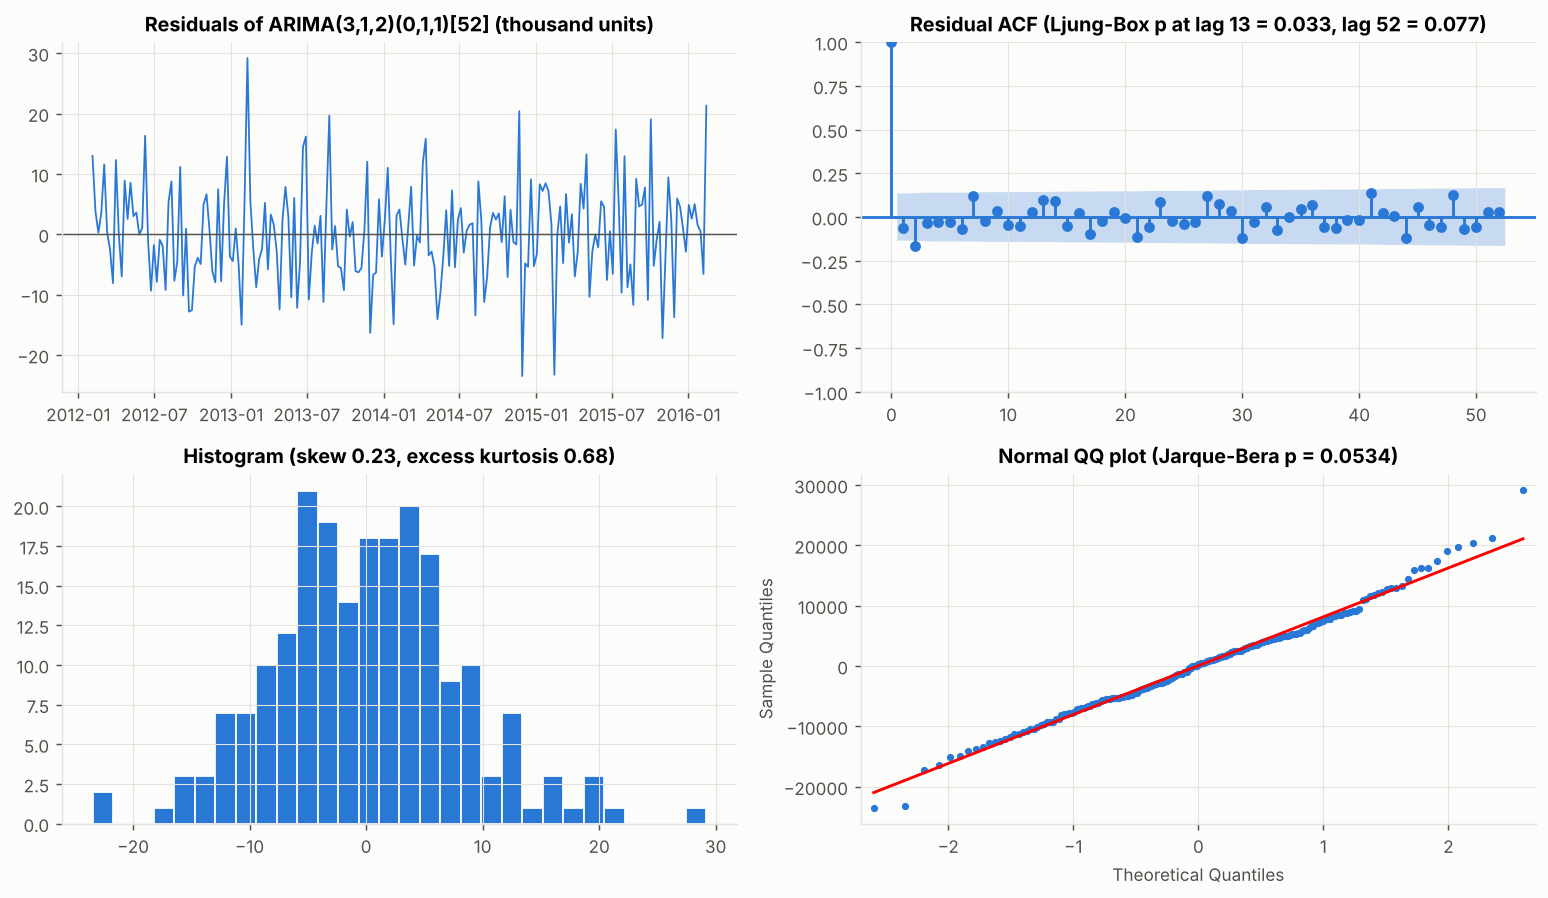

{
 "model": "ARIMA(3,1,2)(0,1,1)[52]",
 "coef": {
  "ar1": -0.034305022624484094,
  "ar2": -0.9219560889871646,
  "ar3": -0.2915233753943491,
  "ma1": -0.2524595917957442,
  "ma2": 0.9596169662307886,
  "sma1": -0.4359792394902074
 },
 "n_resid": 211,
 "resid_mean": 52.840498689602256,
 "resid_sd": 8097.082333809726,
 "ljung_box_p": {
  "4": NaN,
  "8": 0.0028220547782724643,
  "13": 0.032566708426697004,
  "26": 0.14308786620374017,
  "52": 0.0773158178801297
 },
 "jarque_bera_p": 0.05341261651187169,
 "shapiro_p": 0.2605777308598204,
 "skew": 0.22913278542608356,
 "excess_kurtosis": 0.6756231137822919,
 "largest_abs_resid_weeks": [
  "2013-02-09",
  "2014-11-29",
  "2015-02-14",
  "2016-02-13",
  "2014-11-22"
 ]
}


,lag,lb_stat,lb_pvalue
0,4,7.1591,NaN
1,8,11.7406,0.0028
2,13,15.2805,0.0326
3,26,26.7281,0.1431
4,52,60.2533,0.0773


In [7]:
show("09_sarima_residual_diagnostics.png")
print(json.dumps(S["diagnostics"], indent=1))
display(pd.read_csv("reports/tables/sarima_total_ljung_box.csv").round(4))

**Reading it honestly**
- **Autocorrelation:** Ljung-Box rejects white noise at lags 8 (p = 0.003) and 13 (p = 0.033), but not at lags 26 (p = 0.14) or 52 (p = 0.08). Lag 4 is not testable (degrees of freedom ≤ 0 after 6 estimated parameters). The visible culprit is a lag-2 spike (-0.16). The differenced data had lag-2 = -0.59 and lag-4 = +0.65 (a ~4-week cycle), so a leftover of the **monthly SNAP/payday rhythm**, which a 52-week seasonal model cannot express, is the most plausible explanation. **The model has captured the annual structure but not all short-cycle structure.** This is evidence for adding exogenous calendar regressors (DHR-ARIMAX / LightGBM), not for adding more ARMA terms.
- **No over-differencing alarm:** there is no large negative lag-1 residual autocorrelation.
- **Normality:** skew 0.23, excess kurtosis 0.68, Jarque-Bera p = 0.053, Shapiro p = 0.26. This is approximately normal with slightly heavy tails, so Gaussian intervals are a reasonable approximation.
- The largest residuals fall in Feb 2013/2015/2016 and late Nov 2014 (Super Bowl / Thanksgiving weeks shifting relative to a fixed 52-week lag).

## 5. Out-of-sample accuracy and interval calibration

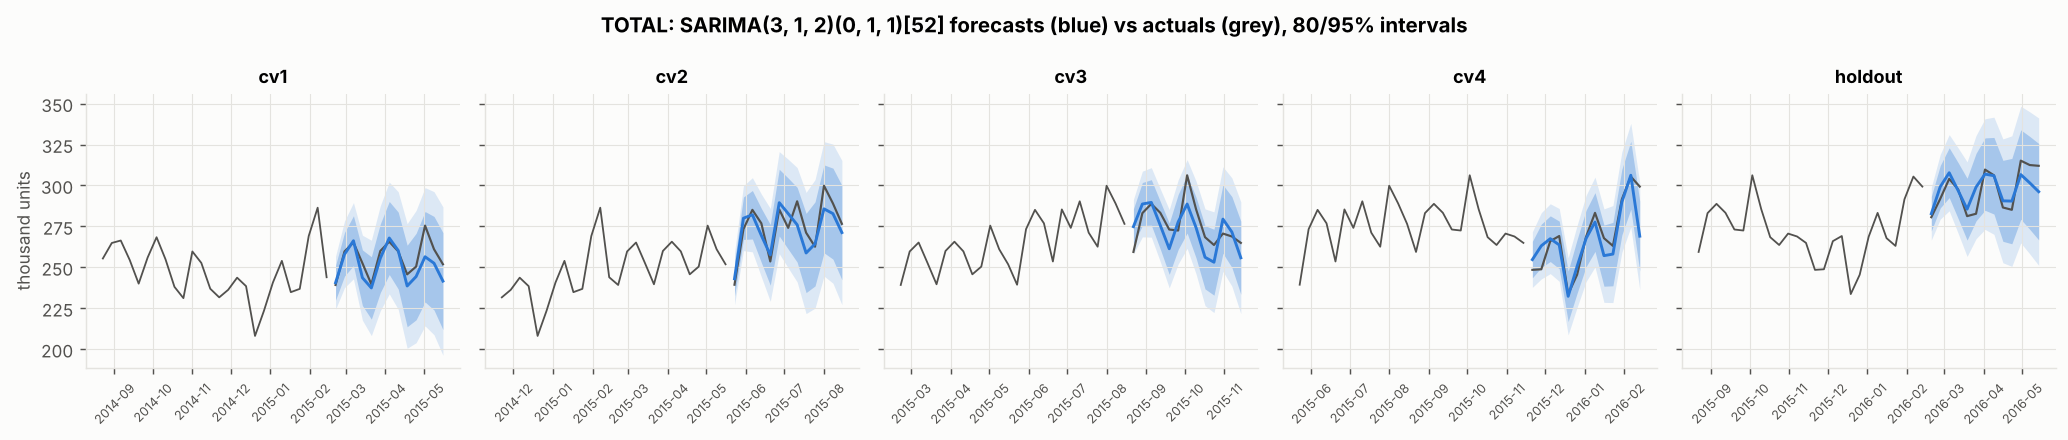

,origin,MAE,WAPE,MASE,Bias,cov80,cov95
0,cv1,5660.7640,0.0221,0.2299,-0.0190,1.0000,1.0
1,cv2,7060.4525,0.0257,0.3036,-0.0095,1.0000,1.0
2,cv3,9135.9547,0.0331,0.4022,-0.0115,0.9231,1.0
3,cv4,6861.6347,0.0256,0.3011,-0.0095,0.8462,1.0
4,holdout,6315.7222,0.0212,0.2745,0.0011,1.0000,1.0


coverage over all 65 forecast weeks: {'cov80': 0.953846153846154, 'cov95': 1.0, 'n_points': 65}


In [8]:
show("09b_sarima_total_windows.png")
display(pd.DataFrame(S["fold_metrics_chosen"]).round(4))
print("coverage over all 65 forecast weeks:", S["coverage_chosen_all_windows"])

**Observed:** WAPE is 2.1-3.3% per 13-week window. Bias is slightly negative in the CV folds (-1% to -2%), i.e. a small under-forecast during growth, and about 0 on the holdout.
**Intervals are too wide:** 95% of actual weeks fell inside the nominal 80% interval and 100% inside the 95% interval (65 points). The intervals are **conservative**, probably because σ² absorbs the 2012 level-shift period and the unmodelled monthly cycle. For inventory this would mean too much safety stock, which is why the inventory module sizes safety stock from **CV forecast errors**, not from model-implied intervals.

## 6. The seasonal-period problem (s = 52) and how it was handled
1. **The year is 52.18 weeks, not 52.** A lag-52 seasonal term drifts by about 1 day per year (and by 1 week in 53-week years), so holidays slide relative to "same week last year".
2. **Computation:** the SARIMA state vector grows with s. statsmodels' `SARIMAX(…, seasonal_order=(P,1,Q,52))` did not finish a single fit within 10 minutes in this environment (with other jobs running), while statsforecast's implementation fits in about 1-2 s.
3. **Estimation:** each seasonal parameter is estimated from only about 4 annual repetitions.

**What we did:** (a) kept classical SARIMA with s = 52 as the benchmark model (fast engine, AutoARIMA order search); (b) added **dynamic harmonic regression** (`DHR-ARIMA`): ARIMA errors + Fourier terms with period 52.18 (K chosen by AICc on pre-CV data) + holiday-week dummies + SNAP-day counts. It handles the non-integer period, moving holidays and the monthly SNAP cycle with few parameters. Notebook 04 compares both under the same protocol.
(Monthly granularity was rejected: it would leave about 64 points and blur the Christmas and Thanksgiving weeks.)